
# Iris Flower Classification

## Objective
Build a machine learning model that predicts the species of an iris flower using its sepal and petal measurements.

## Algorithms
- Logistic Regression
- K-Nearest Neighbors (KNN)
- Decision Tree Classifier

## Evaluation
Compare the models using accuracy, precision, recall, F1-score, and a confusion matrix.


## Import Libraries

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Data Loading

Load the Iris dataset and inspect its structure, columns, and sample records before preparing it for modeling.


In [39]:
df = pd.read_csv('../data/iris.csv')


## 2. Data Inspection

Inspect the dataset to understand its structure, features, data types, and statistical properties before performing exploratory data analysis.


In [40]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [41]:
print("Dataset Shape:",df.shape)
print("Number of rows:",df.shape[0])
print("Number of columns:",df.shape[1])

Dataset Shape: (150, 5)
Number of rows: 150
Number of columns: 5


In [42]:
print('Column Names:')
print(df.columns.tolist())

Column Names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [44]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



## 3. Data Quality Check

Check for missing values and duplicate records to understand whether the dataset requires cleaning before exploratory data analysis.


In [45]:
print('Missing Values in each columns:')
print(df.isnull().sum())

Missing Values in each columns:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [46]:
print('Duplicate Rows:')
print(df.duplicated().sum())

Duplicate Rows:
3


In [47]:

print(df[df.duplicated(keep=False)])


     sepal_length  sepal_width  petal_length  petal_width         species
9             4.9          3.1           1.5          0.1     Iris-setosa
34            4.9          3.1           1.5          0.1     Iris-setosa
37            4.9          3.1           1.5          0.1     Iris-setosa
101           5.8          2.7           5.1          1.9  Iris-virginica
142           5.8          2.7           5.1          1.9  Iris-virginica


In [48]:

print(df["species"].value_counts())


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64



## 4. Data Cleaning

Remove exact duplicate records while preserving the original dataset. Verify the number of remaining records after cleaning.


In [49]:

df_clean = df.drop_duplicates().copy()


In [50]:

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Remaining duplicate rows:", df_clean.duplicated().sum())


Original dataset shape: (150, 5)
Cleaned dataset shape: (147, 5)
Remaining duplicate rows: 0



## 5. Exploratory Data Analysis (EDA)

Explore the distributions, relationships, and patterns in the Iris dataset to understand how the measurements differ across species.



Analyze the number of records for each iris species to understand the class distribution after removing duplicate rows.


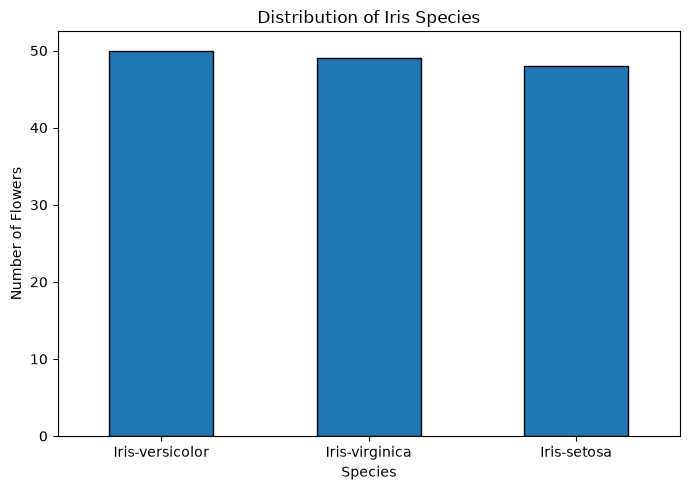

In [51]:

species_counts = df_clean["species"].value_counts()

species_counts.plot(kind="bar", figsize=(7, 5), edgecolor="black")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("../outputs/species_distribution.png", dpi=300, bbox_inches="tight")
plt.show()



Analyze the distributions of sepal length, sepal width, petal length, and petal width using histograms.


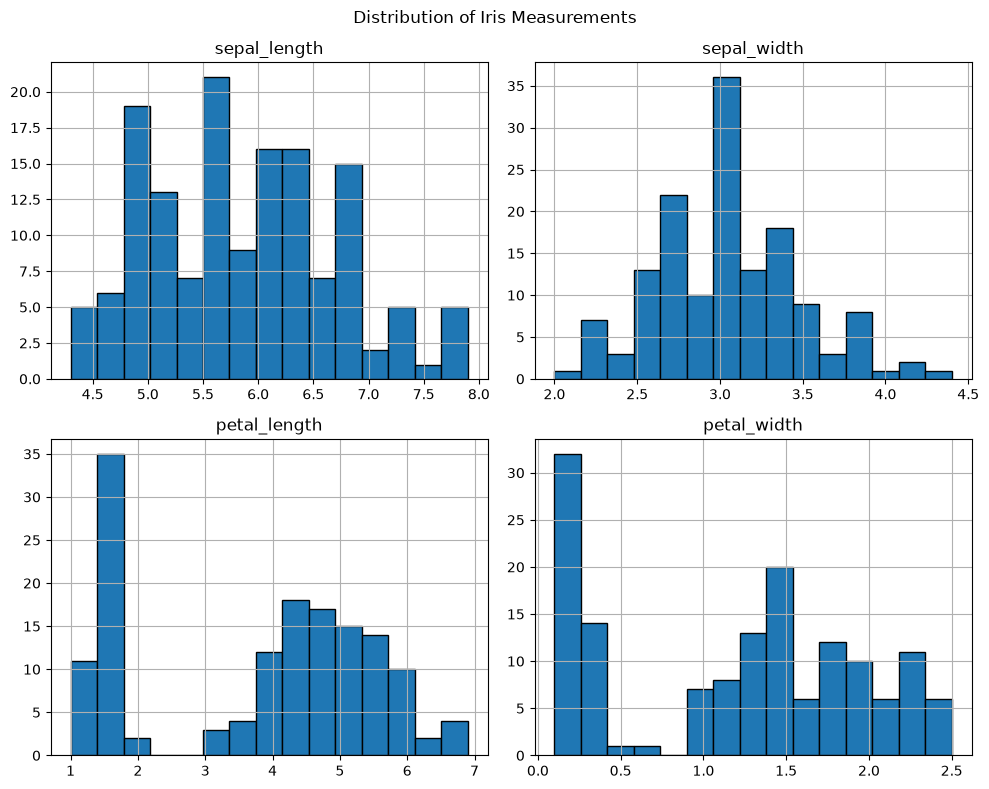

In [52]:
df_clean[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
].hist(figsize=(10, 8), bins=15, edgecolor="black")

plt.suptitle("Distribution of Iris Measurements")
plt.tight_layout()

plt.savefig("../outputs/measurement_distributions.png", dpi=300, bbox_inches="tight")
plt.show()


Compare the distributions of flower measurements across iris species using box plots to identify differences in their ranges, medians, and potential outliers.


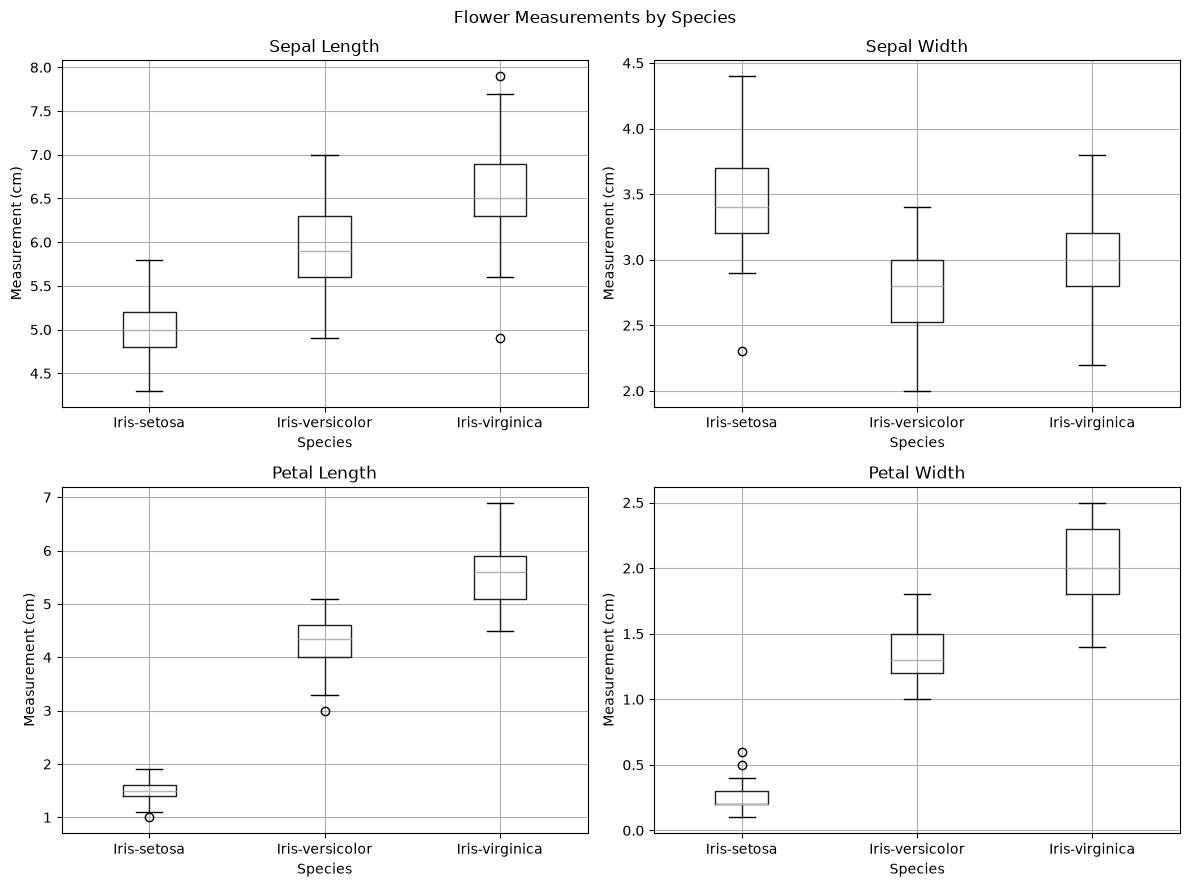

In [53]:
features = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for feature, ax in zip(features, axes.flatten()):
    df_clean.boxplot(
        column=feature,
        by="species",
        ax=ax
    )
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Species")
    ax.set_ylabel("Measurement (cm)")

fig.suptitle("Flower Measurements by Species")
plt.tight_layout()

plt.savefig("../outputs/measurements_by_species_boxplots.png",
            dpi=300, bbox_inches="tight")
plt.show()


Examine relationships between numerical features and compare their distributions across iris species using a pair plot.


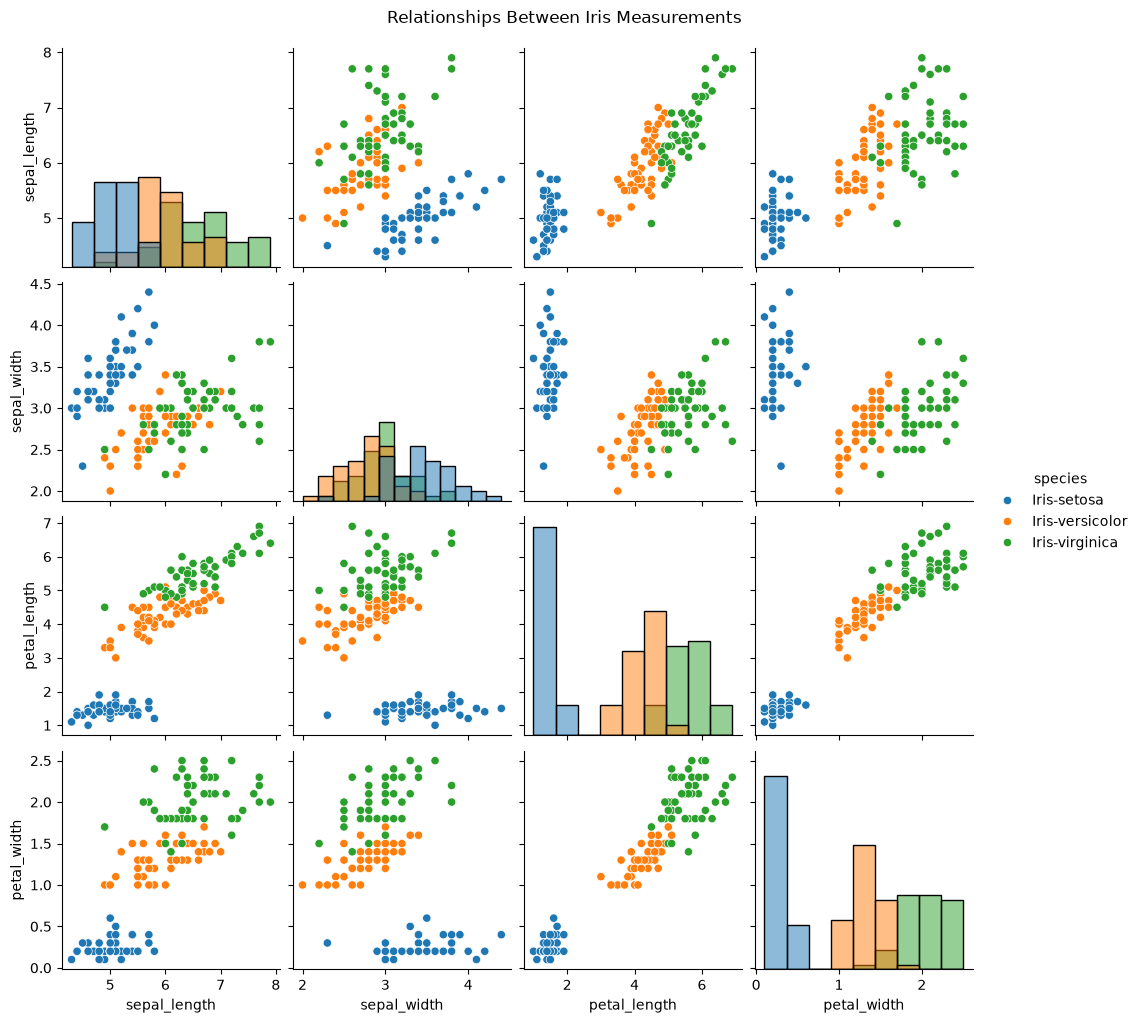

In [54]:

pair_plot = sns.pairplot(
    df_clean,
    vars=[
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width"
    ],
    hue="species",
    diag_kind="hist"
)

pair_plot.fig.suptitle(
    "Relationships Between Iris Measurements",
    y=1.02
)

pair_plot.savefig(
    "../outputs/feature_relationships_pairplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



Analyze correlations between numerical features using a heatmap to identify strong positive and negative relationships between flower measurements.


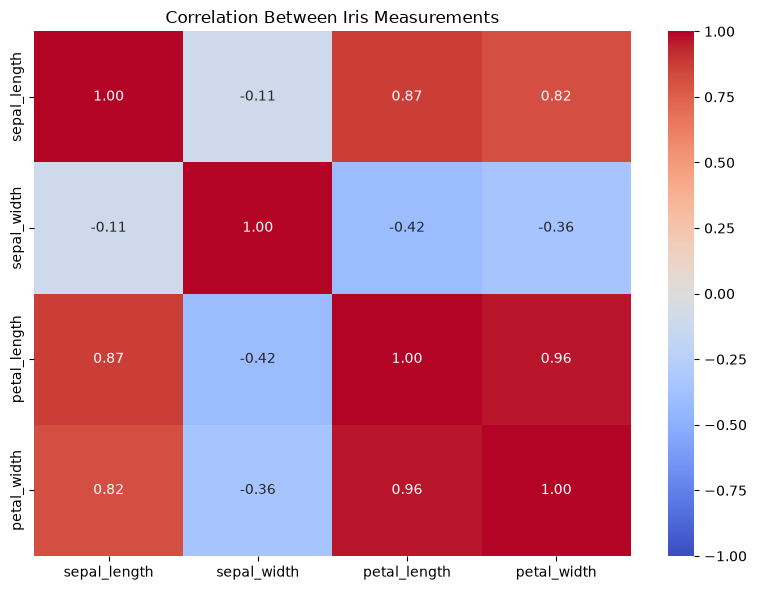

In [55]:
correlation = df_clean[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Iris Measurements")
plt.tight_layout()

plt.savefig(
    "../outputs/feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Model Training and Evaluation

Prepare the input features and target variable, split the dataset into training and testing sets, and evaluate classification models to identify the most suitable model for predicting iris species.


In [56]:

X = df_clean[
    ["sepal_length", "sepal_width", "petal_length", "petal_width"]
]

y = df_clean["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (147, 4)
Target shape: (147,)



### Train-Test Split

Split the dataset into training and testing sets to evaluate model performance on unseen data. Use stratified sampling to preserve the species distribution in both sets.


In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (117, 4)
Testing features: (30, 4)
Training targets: (117,)
Testing targets: (30,)



### Logistic Regression

Train a Logistic Regression classifier to predict iris species from sepal and petal measurements.


In [58]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(max_iter=200)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

print("Actual species:")
print(y_test.values)

print("\nPredicted species:")
print(y_pred_logistic)

Actual species:
<StringArray>
['Iris-versicolor', 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',
  'Iris-virginica', 'Iris-versicolor', 'Iris-versicolor',     'Iris-setosa',
  'Iris-virginica',  'Iris-virginica',     'Iris-setosa',     'Iris-setosa',
     'Iris-setosa', 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',
 'Iris-versicolor',     'Iris-setosa',  'Iris-virginica',     'Iris-setosa',
 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',     'Iris-setosa',
 'Iris-versicolor', 'Iris-versicolor',  'Iris-virginica',  'Iris-virginica',
  'Iris-virginica', 'Iris-versicolor']
Length: 30, dtype: str

Predicted species:
['Iris-versicolor' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-virginica' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Iri


### Logistic Regression Evaluation

Evaluate the Logistic Regression model using test-set accuracy to measure the proportion of correctly classified iris flowers.



In [59]:
from sklearn.metrics import accuracy_score

accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", round(accuracy_logistic, 4))
print("Accuracy Percentage:", round(accuracy_logistic * 100, 2), "%")

Logistic Regression Accuracy: 0.9667
Accuracy Percentage: 96.67 %


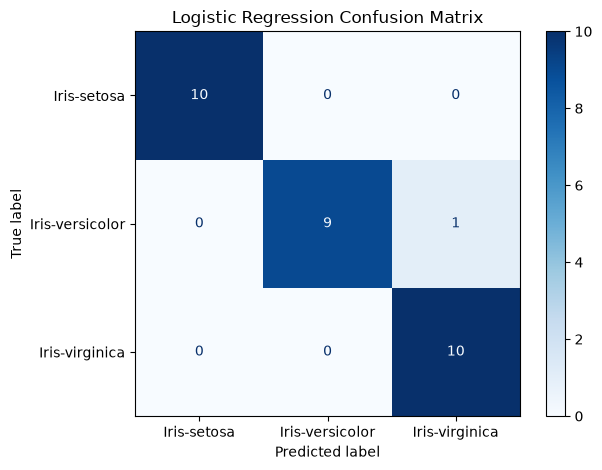

In [60]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "../outputs/logistic_regression_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### K-Nearest Neighbors (KNN)

Train a K-Nearest Neighbors classifier to predict iris species based on the measurements of nearby flowers.


In [61]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

print("Actual species:")
print(y_test.values)

print("\nPredicted species:")
print(y_pred_knn)

Actual species:
<StringArray>
['Iris-versicolor', 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',
  'Iris-virginica', 'Iris-versicolor', 'Iris-versicolor',     'Iris-setosa',
  'Iris-virginica',  'Iris-virginica',     'Iris-setosa',     'Iris-setosa',
     'Iris-setosa', 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',
 'Iris-versicolor',     'Iris-setosa',  'Iris-virginica',     'Iris-setosa',
 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',     'Iris-setosa',
 'Iris-versicolor', 'Iris-versicolor',  'Iris-virginica',  'Iris-virginica',
  'Iris-virginica', 'Iris-versicolor']
Length: 30, dtype: str

Predicted species:
['Iris-versicolor' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-virginica' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Ir


### KNN Evaluation

Evaluate the KNN model using test-set accuracy to measure the proportion of correctly classified iris flowers.



In [62]:
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", round(accuracy_knn, 4))
print("Accuracy Percentage:", round(accuracy_knn * 100, 2), "%")

KNN Accuracy: 1.0
Accuracy Percentage: 100.0 %



### Decision Tree Classifier

Train a Decision Tree classifier to predict iris species using flower measurements and evaluate its predictive performance.


In [63]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Actual species:")
print(y_test.values)

print("\nPredicted species:")
print(y_pred_tree)

Actual species:
<StringArray>
['Iris-versicolor', 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',
  'Iris-virginica', 'Iris-versicolor', 'Iris-versicolor',     'Iris-setosa',
  'Iris-virginica',  'Iris-virginica',     'Iris-setosa',     'Iris-setosa',
     'Iris-setosa', 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',
 'Iris-versicolor',     'Iris-setosa',  'Iris-virginica',     'Iris-setosa',
 'Iris-versicolor',  'Iris-virginica',     'Iris-setosa',     'Iris-setosa',
 'Iris-versicolor', 'Iris-versicolor',  'Iris-virginica',  'Iris-virginica',
  'Iris-virginica', 'Iris-versicolor']
Length: 30, dtype: str

Predicted species:
['Iris-versicolor' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-virginica' 'Iris-virginica' 'Iris-versicolor' 'Iris-setosa'
 'Iris-virginica' 'Iris-virginica' 'Iris-setosa' 'Iris-setosa'
 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-setosa'
 'Iris-versicolor' 'Iri


### Decision Tree Classifier Evaluation

Evaluate the Decision Tree Classifier model using test-set accuracy to measure the proportion of correctly classified iris flowers.



In [64]:
accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", round(accuracy_tree, 4))
print("Accuracy Percentage:", round(accuracy_tree * 100, 2), "%")

Decision Tree Accuracy: 0.9333
Accuracy Percentage: 93.33 %



## 7. Model Performance Comparison

Compare the test accuracy of Logistic Regression, K-Nearest Neighbors, and Decision Tree to identify the best-performing classifier.


In [65]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "K-Nearest Neighbors",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_logistic,
        accuracy_knn,
        accuracy_tree
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

display(results)

,Model,Accuracy
0,K-Nearest Neighbors,1.000000
1,Logistic Regression,0.966667
2,Decision Tree,0.933333


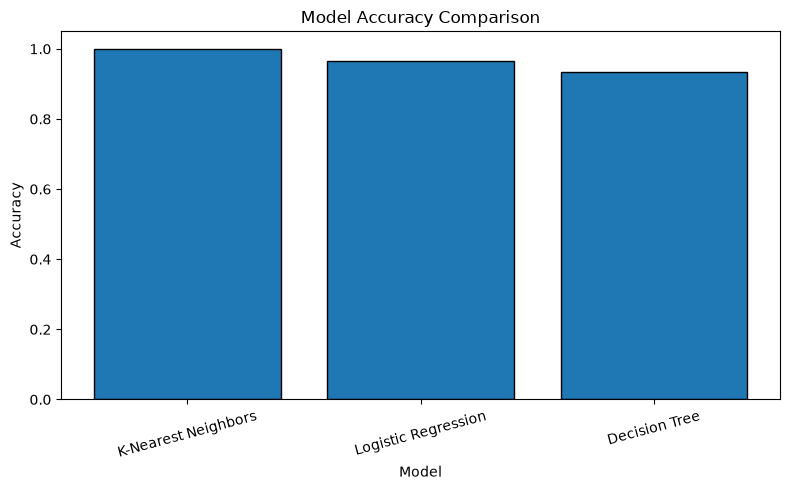

In [66]:
plt.figure(figsize=(8, 5))

plt.bar(
    results["Model"],
    results["Accuracy"],
    edgecolor="black"
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "../outputs/model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 8. Detailed Model Evaluation

Evaluate each classifier using precision, recall, and F1-score with macro averaging. These metrics provide a more detailed comparison of performance across the three iris species.


In [67]:
from sklearn.metrics import precision_score, recall_score, f1_score

predictions = {
    "Logistic Regression": y_pred_logistic,
    "K-Nearest Neighbors": y_pred_knn,
    "Decision Tree": y_pred_tree
}

evaluation_results = []

for model_name, predictions_model in predictions.items():
    evaluation_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions_model),
        "Precision": precision_score(
            y_test, predictions_model, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions_model, average="macro"
        ),
        "F1-Score": f1_score(
            y_test, predictions_model, average="macro"
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9667,0.9697,0.9667,0.9666
1,K-Nearest Neighbors,1.0000,1.0000,1.0000,1.0000
2,Decision Tree,0.9333,0.9333,0.9333,0.9333


In [68]:
evaluation_df.to_csv(
    "../outputs/model_evaluation_results.csv",
    index=False
)


## 9. Confusion Matrix Analysis

Visualize the confusion matrix of each classifier to examine correct predictions and misclassifications across the three iris species.


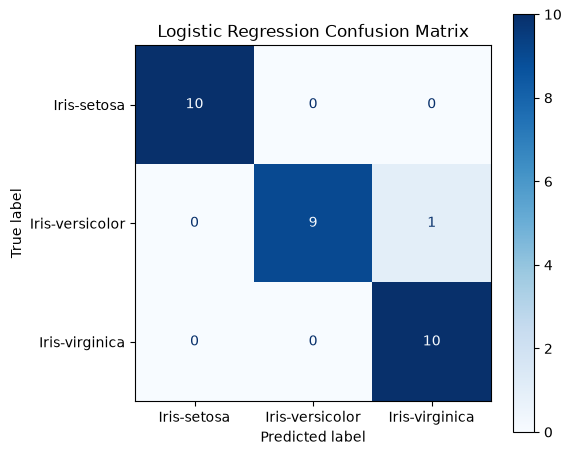

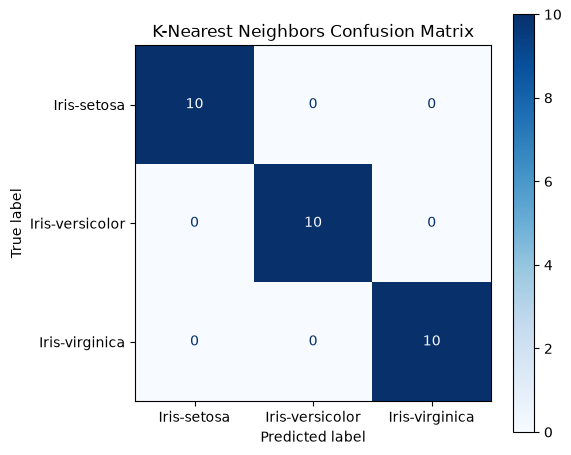

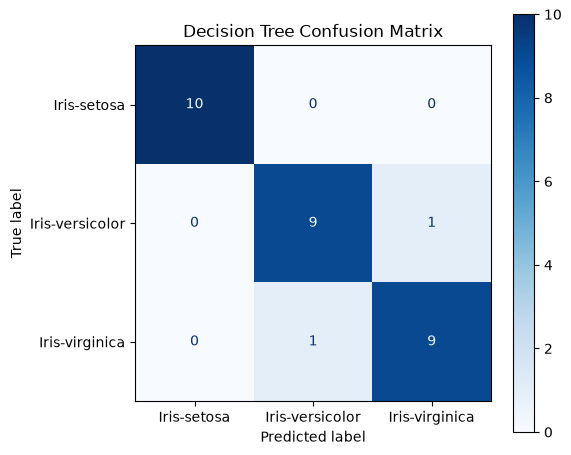

In [69]:
from sklearn.metrics import ConfusionMatrixDisplay

models_predictions = {
    "Logistic Regression": y_pred_logistic,
    "K-Nearest Neighbors": y_pred_knn,
    "Decision Tree": y_pred_tree
}

for model_name, predictions_model in models_predictions.items():

    fig, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions_model,
        labels=["Iris-setosa", "Iris-versicolor", "Iris-virginica"],
        cmap="Blues",
        ax=ax
    )

    ax.set_title(f"{model_name} Confusion Matrix")
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_")
    fig.savefig(
        f"../outputs/{filename}_confusion_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


## 10. Best Model Selection and Saving

Select the best-performing classifier using macro F1-score and accuracy, then save the trained model for future predictions.


In [70]:
best_model_name = evaluation_df.sort_values(
    by=["F1-Score", "Accuracy"],
    ascending=False
).iloc[0]["Model"]

trained_models = {
    "Logistic Regression": logistic_model,
    "K-Nearest Neighbors": knn_model,
    "Decision Tree": tree_model
}

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)
print("Best Model Accuracy:",
      round(accuracy_score(y_test, best_model.predict(X_test)) * 100, 2), "%")

Best Model: K-Nearest Neighbors
Best Model Accuracy: 100.0 %


In [71]:
import joblib

joblib.dump(
    best_model,
    "../models/best_iris_model.joblib"
)

print("Best model saved successfully!")

Best model saved successfully!



### Saved Model Verification

Reload the saved model and verify that it produces the same predictions as the original trained model.


In [72]:
loaded_model = joblib.load(
    "../models/best_iris_model.joblib"
)

original_predictions = best_model.predict(X_test)
loaded_predictions = loaded_model.predict(X_test)

print(
    "All predictions match:",
    np.array_equal(original_predictions, loaded_predictions)
)

All predictions match: True



### Prediction on a New Flower

Use the saved model to predict the species of a new iris flower from its sepal and petal measurements.


In [73]:
new_flower = pd.DataFrame({
    "sepal_length": [5.1],
    "sepal_width": [3.5],
    "petal_length": [1.4],
    "petal_width": [0.2]
})

In [74]:
prediction = loaded_model.predict(new_flower)

print("Predicted species:", prediction[0])

if hasattr(loaded_model, "predict_proba"):
    probabilities = loaded_model.predict_proba(new_flower)[0]

    probability_results = pd.DataFrame({
        "Species": loaded_model.classes_,
        "Probability": probabilities
    })

    display(probability_results.round(4))

Predicted species: Iris-setosa


,Species,Probability
0,Iris-setosa,1.0
1,Iris-versicolor,0.0
2,Iris-virginica,0.0



## 11. Conclusion

Three classification algorithms—Logistic Regression, K-Nearest Neighbors, and Decision Tree—were trained and evaluated on the Iris dataset.

Their performance was compared using accuracy, precision, recall, F1-score, and confusion matrices. The best model was selected based on the evaluation results, saved, reloaded, and tested on a new flower sample.

The final results and model performance should be interpreted using the actual outputs generated by this notebook.
